In [4]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
def anharmonic_potential(x, lam=0.1):

    potential = 0.5*x**2 + lam*x**4

    return potential

In [6]:
def hamiltonian_matrix(n, dx, potential_values):
    kinetic_matrix = np.zeros((n,n))
    for i in range(n):
        kinetic_matrix[i,i] = -2
        if i+1 < n:
            kinetic_matrix[i+1,i] = 1
            kinetic_matrix[i,i+1] = 1

    kinetic_energy = -0.5*kinetic_matrix/(dx**2)
    potential_energy = np.diag(potential_values)
    hamiltonian = kinetic_energy + potential_energy

    return hamiltonian

In [7]:
def solve_anharmonic(L, interior_points, state_number, lam=0.1):
    dx = L/(interior_points+1)
    x = np.linspace(-L/2, L/2, interior_points+2)
    x_interior = x[1:-1]
    potential_values = anharmonic_potential(x_interior, lam)
    H = hamiltonian_matrix(interior_points, dx, potential_values)

    energies, eigenvectors = np.linalg.eigh(H)

    psi = eigenvectors[:,state_number]
    psi = psi/np.sqrt(np.sum(psi**2)*dx)
    probability_density = psi**2

    return x_interior, psi, probability_density, energies[state_number]

State: 0
Energy: 0.5591286431408558
State: 1
Energy: 1.7693976812252765
State: 2
Energy: 3.1383082582946384
State: 3
Energy: 4.6281949890485885


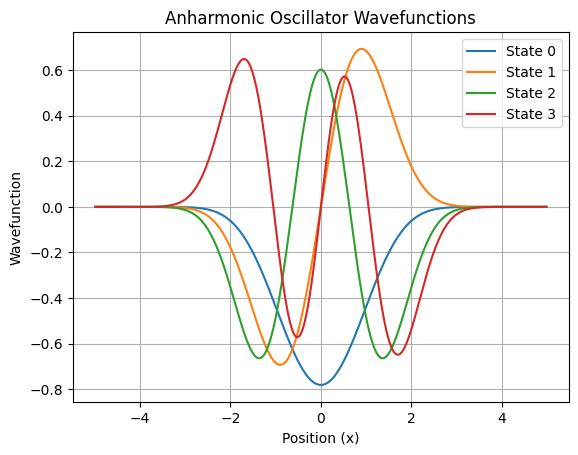

In [8]:
L = 10
interior_points = 500

for state_number in range(4):
    x, psi, probability_density, energy = solve_anharmonic(
        L, interior_points, state_number
    )

    print("State:", state_number)
    print("Energy:", energy)

    plt.plot(x, psi, label=f"State {state_number}")

plt.xlabel("Position (x)")
plt.ylabel("Wavefunction")
plt.title("Anharmonic Oscillator Wavefunctions")
plt.legend()
plt.grid()
plt.show()

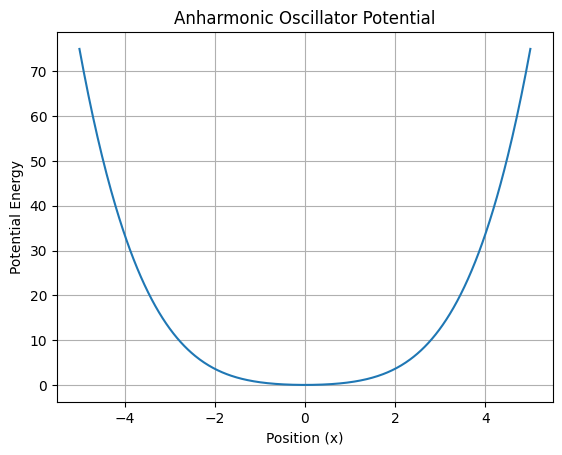

In [9]:
x = np.linspace(-5,5,500)
V = anharmonic_potential(x)
plt.plot(x,V)
plt.xlabel("Position (x)")
plt.ylabel("Potential Energy")
plt.title("Anharmonic Oscillator Potential")
plt.grid()
plt.show()